<a href="https://colab.research.google.com/github/sazzadsazid/Bd-freshwater-fish-swin-classifier/blob/main/BD_Freshwater_Fish_Swin_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Mon Nov 23 12:44:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import shutil
import zipfile
from pathlib import Path

ZIP_PATH = Path(
    "/content/drive/MyDrive/fishdataset/"
    "BD-Freshwater-Fish An Image Dataset from Bangladesh for AI-Powered Automatic Fish Species Classification and Detection toward Smart Aquaculture.zip"
)

# Fallback in case Drive altered spaces/punctuation in the long filename
if not ZIP_PATH.exists():
    candidates = list(Path("/content/drive/MyDrive/fishdataset").glob("*.zip"))
    if not candidates:
        raise FileNotFoundError("No .zip file found in /content/drive/MyDrive/fishdataset/")
    ZIP_PATH = candidates[0]
    print(f"Using detected zip file: {ZIP_PATH}")

RAW_DIR = Path("/content/raw_extract")
CLEAN_DIR = Path("/content/clean_dataset")

# Start fresh locally
for d in (RAW_DIR, CLEAN_DIR):
    if d.exists():
        shutil.rmtree(d)
    d.mkdir(parents=True)

# 1. Unzip the outer archive (any nested normal folders inside are handled automatically)
print("Extracting main zip...")
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(RAW_DIR)

# 2. Recursively find all inner species .zip files
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
inner_zips = sorted(
    p for p in RAW_DIR.rglob("*.zip")
    if "__MACOSX" not in p.parts and not p.name.startswith("._")
)

if not inner_zips:
    raise RuntimeError("No inner .zip files found. Check if the species files are .rar or .7z.")

# Safety check: avoid mixing Original and Augmented folders if both exist
parent_dirs = sorted({p.parent for p in inner_zips})
if len(parent_dirs) > 1:
    print("Multiple folders containing species zips found:")
    for d in parent_dirs:
        print(" -", d.relative_to(RAW_DIR))
    orig_dirs = [d for d in parent_dirs if "original" in str(d).lower()]
    target_parent = orig_dirs[0] if orig_dirs else parent_dirs[0]
    print(f"Using only: {target_parent.relative_to(RAW_DIR)}")
    inner_zips = [p for p in inner_zips if p.parent == target_parent]

print(f"\nExtracting {len(inner_zips)} species zips...")

# 3. Extract images into /content/clean_dataset/<species>/
for inner_zip in inner_zips:
    species_name = inner_zip.stem.strip()
    species_dir = CLEAN_DIR / species_name
    species_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(inner_zip, "r") as zf:
        for idx, member in enumerate(zf.infolist()):
            if member.is_dir():
                continue
            member_path = Path(member.filename)
            if "__MACOSX" in member_path.parts or member_path.name.startswith("._"):
                continue
            if member_path.suffix.lower() not in IMAGE_EXTS:
                continue

            out_path = species_dir / member_path.name
            if out_path.exists():
                out_path = species_dir / f"{member_path.stem}_{idx}{member_path.suffix}"

            with zf.open(member) as src, open(out_path, "wb") as dst:
                shutil.copyfileobj(src, dst)

# Free up Colab local disk space now that clean_dataset is built
shutil.rmtree(RAW_DIR)

# 4. Verify each species folder and image count
print("\nReady! Final dataset in /content/clean_dataset:")
total = 0
for folder in sorted(CLEAN_DIR.iterdir()):
    if folder.is_dir():
        count = len(list(folder.iterdir()))
        total += count
        print(f"  {folder.name}: {count} images")
print(f"Total images: {total}")

Extracting main zip...

Extracting 12 species zips...

Ready! Final dataset in /content/clean_dataset:
  Black Rohu: 306 images
  Catla: 432 images
  Common Carp: 517 images
  Freshwater Shark: 60 images
  Grass Carp: 410 images
  Long-whiskered Catfish: 61 images
  Mirror Carp: 415 images
  Mrigal: 405 images
  Nile Tilapia: 409 images
  Rohu: 514 images
  Silver Carp: 400 images
  Striped Catfish: 460 images
Total images: 4389


In [14]:
from pathlib import Path
from PIL import Image

# Disable the warning while we intentionally open the 108-megapixel photos
Image.MAX_IMAGE_PIXELS = None

CLEAN_DIR = Path("/content/clean_dataset")
MAX_SIZE = 512  # Over 2x larger than Swin's 224x224 input, so zero detail is lost

resized_count = 0
total_count = 0

for img_path in sorted(CLEAN_DIR.rglob("*")):
    if not img_path.is_file():
        continue
    total_count += 1
    with Image.open(img_path) as img:
        if max(img.size) > MAX_SIZE:
            img = img.convert("RGB")
            img.thumbnail((MAX_SIZE, MAX_SIZE), Image.Resampling.LANCZOS)
            img.save(img_path, quality=95)
            resized_count += 1

print(f"Checked {total_count} images. Resized {resized_count} huge images down to max {MAX_SIZE}px.")

Checked 4389 images. Resized 4388 huge images down to max 512px.


In [16]:
!pip install -q transformers datasets accelerate scikit-learn

In [17]:
#splitting the dataset
from pathlib import Path
from datasets import DatasetDict, load_dataset

DATA_DIR = "/content/clean_dataset"
assert Path(DATA_DIR).exists(), "clean_dataset is missing! Re-run the unzip cell first."

full_ds = load_dataset("imagefolder", data_dir=DATA_DIR)["train"]

# 70% train, 30% temp (keeping identical class proportions across all 12 species)
split_1 = full_ds.train_test_split(test_size=0.30, stratify_by_column="label", seed=42)
# Split the remaining 30% into 15% validation and 15% test
split_2 = split_1["test"].train_test_split(test_size=0.50, stratify_by_column="label", seed=42)

ds = DatasetDict({
    "train": split_1["train"],
    "val": split_2["train"],
    "test": split_2["test"],
})

labels = ds["train"].features["label"].names
id2label = {i: name for i, name in enumerate(labels)}
label2id = {name: i for i, name in enumerate(labels)}

print(f"Classes ({len(labels)}):", labels)
print(f"Train: {len(ds['train'])} | Val: {len(ds['val'])} | Test: {len(ds['test'])}")

Resolving data files:   0%|          | 0/4389 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Classes (12): ['Black Rohu', 'Catla', 'Common Carp', 'Freshwater Shark', 'Grass Carp', 'Long-whiskered Catfish', 'Mirror Carp', 'Mrigal', 'Nile Tilapia', 'Rohu', 'Silver Carp', 'Striped Catfish']
Train: 3072 | Val: 658 | Test: 659


In [18]:
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight
from torchvision.transforms import (
    CenterCrop,
    ColorJitter,
    Compose,
    Normalize,
    RandomHorizontalFlip,
    RandomResizedCrop,
    Resize,
    ToTensor,
)
from transformers import AutoImageProcessor

In [19]:
MODEL_NAME = "microsoft/swin-tiny-patch4-window7-224"

# 1. Calculate balanced class weights using ONLY the training labels
train_labels = np.array(ds["train"]["label"])
weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(labels)),
    y=train_labels,
)
class_weights = torch.tensor(weights_np, dtype=torch.float32)

print("Class weights (higher = rare species gets a stronger penalty):")
for name, w in zip(labels, weights_np):
    print(f"  {name:24s}: {w:.2f}x")

# 2. Load the Swin Transformer's expected image size and color statistics
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
size = processor.size.get("shortest_edge", processor.size.get("height", 224))
normalize = Normalize(mean=processor.image_mean, std=processor.image_std)

# 3. Define transforms: augmented for training, clean/consistent for val & test
train_tf = Compose([
    RandomResizedCrop(size, scale=(0.75, 1.0)),
    RandomHorizontalFlip(),
    ColorJitter(brightness=0.2, contrast=0.2),
    ToTensor(),
    normalize,
])

eval_tf = Compose([
    Resize(size),
    CenterCrop(size),
    ToTensor(),
    normalize,
])

def apply_train_tf(batch):
    batch["pixel_values"] = [train_tf(img.convert("RGB")) for img in batch["image"]]
    return batch

def apply_eval_tf(batch):
    batch["pixel_values"] = [eval_tf(img.convert("RGB")) for img in batch["image"]]
    return batch

# 4. Attach the transforms to run on-the-fly whenever an image is loaded
ds["train"].set_transform(apply_train_tf)
ds["val"].set_transform(apply_eval_tf)
ds["test"].set_transform(apply_eval_tf)

# 5. Quick sanity check on one processed training image
sample = ds["train"][0]
print(f"\nImage size set to: {size}x{size}")
print("Sample tensor shape:", sample["pixel_values"].shape)
print("Sample label:", id2label[sample["label"]])

Class weights (higher = rare species gets a stronger penalty):
  Black Rohu              : 1.20x
  Catla                   : 0.85x
  Common Carp             : 0.71x
  Freshwater Shark        : 6.10x
  Grass Carp              : 0.89x
  Long-whiskered Catfish  : 5.95x
  Mirror Carp             : 0.88x
  Mrigal                  : 0.90x
  Nile Tilapia            : 0.90x
  Rohu                    : 0.71x
  Silver Carp             : 0.91x
  Striped Catfish         : 0.80x

Image size set to: 224x224
Sample tensor shape: torch.Size([3, 224, 224])
Sample label: Nile Tilapia


In [20]:
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoModelForImageClassification, Trainer

# 1. Confirm the GPU is active before we go any further
if torch.cuda.is_available():
    print("GPU ready:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Running on CPU! Go to Runtime - Change runtime type - T4 GPU.")

GPU ready: Tesla T4


In [21]:


# 2. Load the pretrained Swin Transformer and replace its final layer for our 12 fish species
model = AutoModelForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)

# 3. Custom Trainer that applies our class_weights inside CrossEntropyLoss
class WeightedTrainer(Trainer):
    def __init__(self, class_weights, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels_tensor = inputs["labels"]
        outputs = model(pixel_values=inputs["pixel_values"])
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=self.class_weights.to(logits.device))
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels_tensor.view(-1))
        return (loss, outputs) if return_outputs else loss

# 4. Evaluation function: runs after every epoch on the validation split
def compute_metrics(eval_pred):
    preds = np.argmax(eval_pred.predictions, axis=1)
    refs = eval_pred.label_ids
    return {
        "accuracy": accuracy_score(refs, preds),
        "macro_f1": f1_score(refs, preds, average="macro"),
    }

# 5. Batch packer: stacks individual image tensors into one batch for the GPU
def collate_fn(examples):
    pixel_values = torch.stack([ex["pixel_values"] for ex in examples])
    labels_tensor = torch.tensor([ex["label"] for ex in examples], dtype=torch.long)
    return {"pixel_values": pixel_values, "labels": labels_tensor}

# 6. Quick sanity check on the loaded model
total_params = sum(p.numel() for p in model.parameters())
print(f"Model loaded! Total parameters: {total_params:,}")
print("Output classification layer:", model.classifier)

[transformers] You passed `num_labels=12` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([12])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([12, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Model loaded! Total parameters: 27,528,582
Output classification layer: Linear(in_features=768, out_features=12, bias=True)


In [22]:
from transformers import TrainingArguments

# 1. Confirm GPU is available and explicitly attach our 12 fish species names to the model config
assert torch.cuda.is_available(), "No GPU detected! Go to Runtime -> Change runtime type -> T4 GPU."
model.config.id2label = id2label
model.config.label2id = label2id

SAVE_DIR = "/content/drive/MyDrive/fishdataset/checkpoints/swin_bd_fish"

# 2. Define the training rules and hyperparameters
training_args = TrainingArguments(
    output_dir=SAVE_DIR,
    remove_unused_columns=False,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    weight_decay=0.01,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=10,
    warmup_steps=100,
    fp16=True,
    dataloader_num_workers=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    logging_steps=25,
    report_to="none",
)

# 3. Assemble the Trainer (combines model + data + weighted loss + metrics)
trainer = WeightedTrainer(
    class_weights=class_weights,
    model=model,
    args=training_args,
    train_dataset=ds["train"],
    eval_dataset=ds["val"],
    compute_metrics=compute_metrics,
    data_collator=collate_fn,
)

print("GPU active:", torch.cuda.get_device_name(0))
print("Saved labels in model config:", model.config.id2label)
print("Trainer ready! Total training batches per epoch:", len(trainer.get_train_dataloader()))

GPU active: Tesla T4
Saved labels in model config: {0: 'Black Rohu', 1: 'Catla', 2: 'Common Carp', 3: 'Freshwater Shark', 4: 'Grass Carp', 5: 'Long-whiskered Catfish', 6: 'Mirror Carp', 7: 'Mrigal', 8: 'Nile Tilapia', 9: 'Rohu', 10: 'Silver Carp', 11: 'Striped Catfish'}
Trainer ready! Total training batches per epoch: 96


In [ ]:
# 1. Start fine-tuning the Swin Transformer for 10 epochs (960 steps)
train_result = trainer.train()

# 2. Save the best model (chosen by highest validation Macro F1) and image processor to Drive
BEST_MODEL_DIR = "/content/drive/MyDrive/fishdataset/checkpoints/swin_bd_fish_best"
trainer.save_model(BEST_MODEL_DIR)
processor.save_pretrained(BEST_MODEL_DIR)

print("\nTraining complete!")
print(f"Best model permanently saved to: {BEST_MODEL_DIR}")

In [25]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader
from transformers import AutoModelForImageClassification

Loading saved model from: /content/drive/MyDrive/fishdataset/checkpoints/swin_bd_fish/checkpoint-672


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Updated swin_bd_fish_best with clean Epoch 7 weights.

=== FINAL TEST SET RESULTS (659 unseen images) ===
Test Accuracy : 99.09%
Test Macro F1 : 0.9922

                        precision    recall  f1-score   support

            Black Rohu     1.0000    1.0000    1.0000        46
                 Catla     1.0000    1.0000    1.0000        65
           Common Carp     1.0000    1.0000    1.0000        78
      Freshwater Shark     1.0000    1.0000    1.0000         9
            Grass Carp     0.9667    0.9355    0.9508        62
Long-whiskered Catfish     1.0000    1.0000    1.0000         9
           Mirror Carp     1.0000    1.0000    1.0000        63
                Mrigal     0.9672    0.9833    0.9752        60
          Nile Tilapia     1.0000    1.0000    1.0000        61
                  Rohu     0.9744    0.9870    0.9806        77
           Silver Carp     1.0000    1.0000    1.0000        60
       Striped Catfish     1.0000    1.0000    1.0000        69

             

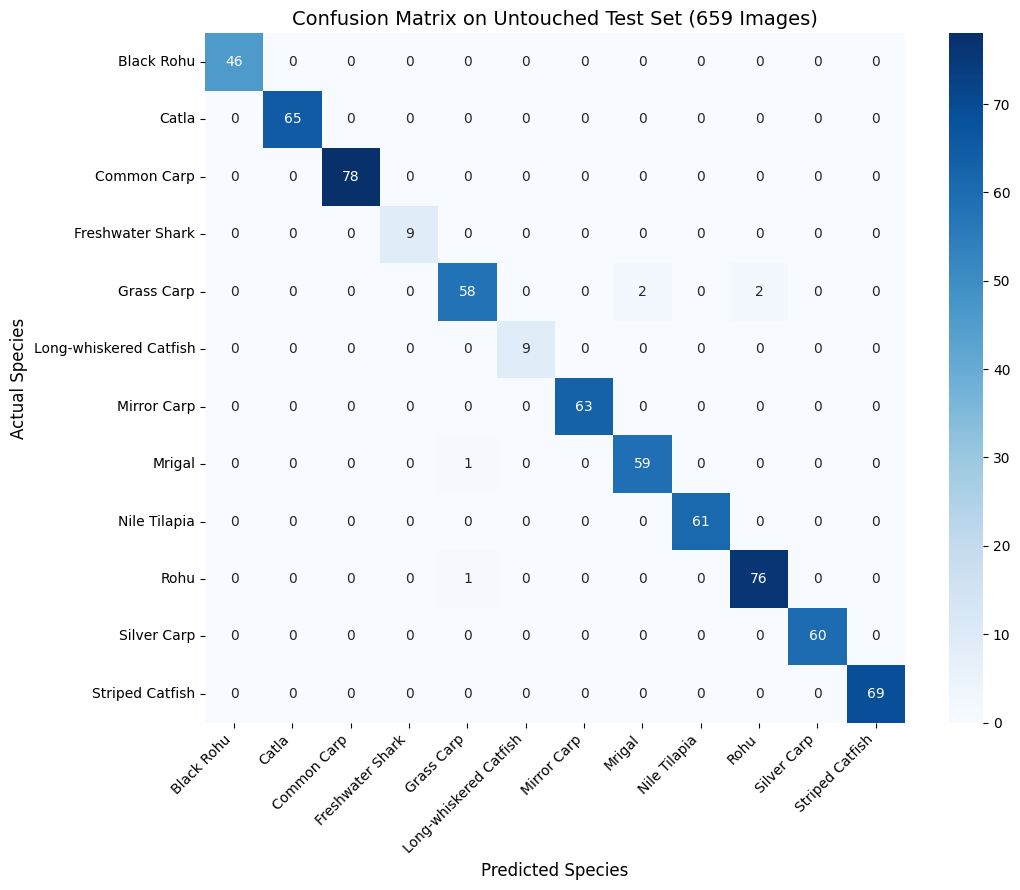

In [26]:
# 1. Load your saved Epoch 7 model from Google Drive
EPOCH7_DIR = Path("/content/drive/MyDrive/fishdataset/checkpoints/swin_bd_fish/checkpoint-672")
BEST_DIR = Path("/content/drive/MyDrive/fishdataset/checkpoints/swin_bd_fish_best")

model_path = EPOCH7_DIR if EPOCH7_DIR.exists() else BEST_DIR
print("Loading saved model from:", model_path)

eval_model = AutoModelForImageClassification.from_pretrained(model_path).cuda()
eval_model.eval()

# Save this clean Epoch 7 copy into swin_bd_fish_best
if model_path == EPOCH7_DIR:
    eval_model.save_pretrained(BEST_DIR)
    processor.save_pretrained(BEST_DIR)
    print("Updated swin_bd_fish_best with clean Epoch 7 weights.")

# 2. Run predictions on all 659 untouched test images
test_loader = DataLoader(ds["test"], batch_size=32, shuffle=False, collate_fn=collate_fn)

all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        pixel_values = batch["pixel_values"].cuda()
        outputs = eval_model(pixel_values=pixel_values)
        preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(batch["labels"].numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 3. Print overall and per-species scores
test_acc = accuracy_score(all_labels, all_preds)
test_f1 = f1_score(all_labels, all_preds, average="macro")

print(f"\n=== FINAL TEST SET RESULTS (659 unseen images) ===")
print(f"Test Accuracy : {test_acc * 100:.2f}%")
print(f"Test Macro F1 : {test_f1:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=labels, digits=4))

# 4. Plot the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(11, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)
plt.xlabel("Predicted Species", fontsize=12)
plt.ylabel("Actual Species", fontsize=12)
plt.title("Confusion Matrix on Untouched Test Set (659 Images)", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
import torch
from google.colab import files
from PIL import Image
from transformers import pipeline

# 1. Load your saved model directly from Google Drive
classifier = pipeline(
    "image-classification",
    model="/content/drive/MyDrive/fishdataset/checkpoints/swin_bd_fish_best",
    device=0 if torch.cuda.is_available() else -1,
)

# 2. Pick any fish photo from your computer to test
uploaded = files.upload()

for filename in uploaded.keys():
    img = Image.open(filename).convert("RGB")
    predictions = classifier(img, top_k=3)
    print(f"\nPredictions for {filename}:")
    for pred in predictions:
        print(f"  {pred['label']:24s} -> {pred['score'] * 100:.2f}%")

Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

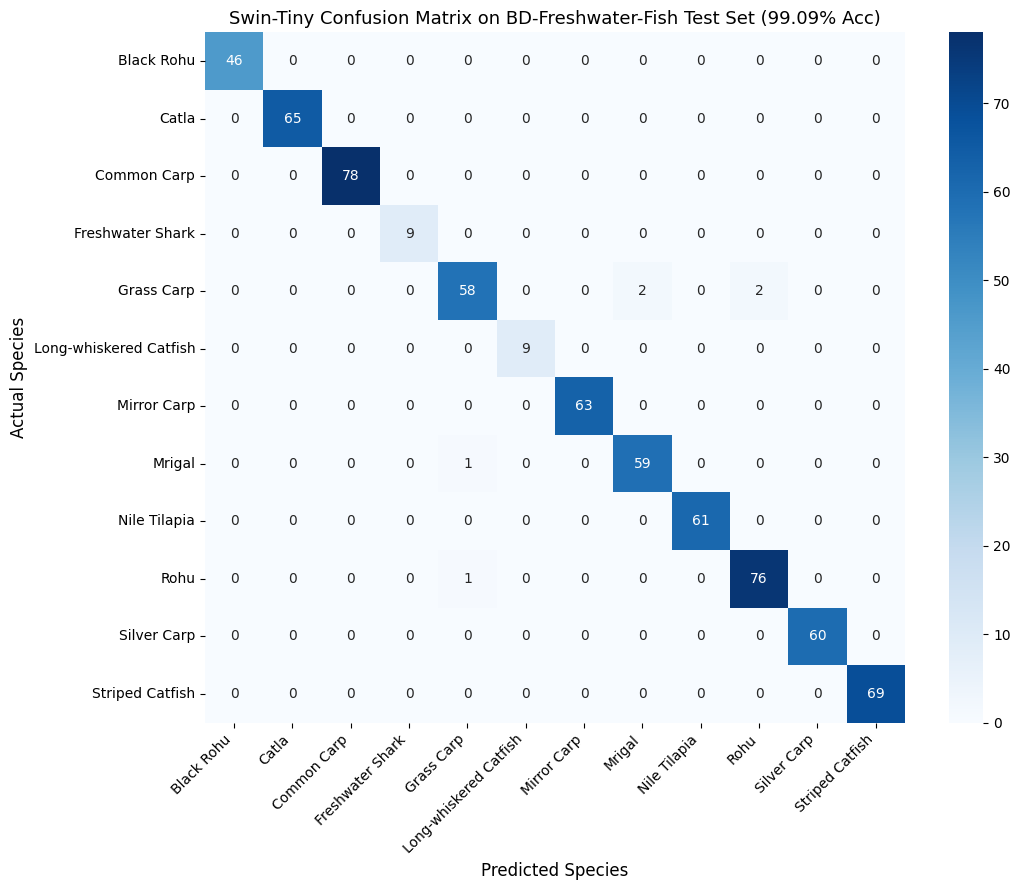

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)
plt.xlabel("Predicted Species", fontsize=12)
plt.ylabel("Actual Species", fontsize=12)
plt.title("Swin-Tiny Confusion Matrix on BD-Freshwater-Fish Test Set (99.09% Acc)", fontsize=13)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
files.download("confusion_matrix.png")